# Project 2 — How many independent things is the stock market doing?

**The question.** A correlation matrix of 470 stocks has about 110,000
distinct entries, estimated from 1,258 days. Most of those entries must be
noise. How many directions in that matrix carry real, shared structure, how
does that number move through time, and does knowing which directions are
noise make a portfolio measurably better?

**Why this project.** The internship's `collapse_metrics.py` asked how many
neurons' worth of independent signal a hidden layer carried: take the
activations, look at the spectrum, summarise it as an effective rank. Swap
"neurons" for "stocks" and "activations" for "daily returns" and it is the
same measurement on a different matrix. What finance adds is something the
internship did not have — an **exact theory of what the spectrum of pure noise
looks like** (random matrix theory), so the null is a formula rather than a
control run.

**Structure**

1. Data and the correlation matrix
2. The Marchenko–Pastur law, verified on simulated noise before it is used
3. The real spectrum against two nulls: how many eigenvalues are signal?
4. What the signal eigenvectors are
5. The internship's rank metrics, ported — and why one number is not enough
6. Through time: when the market collapses onto one direction
7. Does it matter? Denoising the covariance matrix for portfolio construction
8. What was found, and what this cannot tell us

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf

import common as C

C.set_style()
SEED = 0

## 1. Data and the correlation matrix

Same cleaned panel as Project 1. Log returns are used here because they add
across time and are closer to symmetric.

The quantity that governs everything below is the **aspect ratio**
$q = N/T$: stocks per day of data. When $q$ is small there is plenty of data
per parameter and the sample correlation matrix is trustworthy. As $q$
approaches 1 it becomes mostly noise, and above 1 it is not even invertible.

In [2]:
rets = np.log1p(C.clean_returns(C.load_prices()))
tickers = rets.columns
X = rets.to_numpy()
T, N = X.shape
q = N / T
print(f"\nT = {T} days, N = {N} stocks, q = N/T = {q:.3f}")
print(f"distinct correlations to estimate: {N*(N-1)//2:,}   data points: {N*T:,}")


def standardise(x):
    """Zero mean, unit variance per column (per stock)."""
    return (x - x.mean(axis=0)) / x.std(axis=0)


def correlation_spectrum(x):
    """Eigenvalues (descending) and eigenvectors of the correlation matrix of x.

    np.linalg.eigh is the right routine for a symmetric matrix: it guarantees
    real eigenvalues and orthonormal eigenvectors. It returns them ascending,
    hence the flips.
    """
    z = standardise(x)
    corr = z.T @ z / len(z)
    vals, vecs = np.linalg.eigh(corr)
    return vals[::-1], vecs[:, ::-1]


eigvals, eigvecs = correlation_spectrum(X)
print(f"\neigenvalues sum to N: {eigvals.sum():.1f}")
print("largest eight:", np.round(eigvals[:8], 2))

panel: 1258 days x 470 tickers (2013-02-11 to 2018-02-07)
neutralised 9 corporate-action days and 5 bad ticks
largest remaining one-day move: 61.9%

T = 1258 days, N = 470 stocks, q = N/T = 0.374
distinct correlations to estimate: 110,215   data points: 591,260

eigenvalues sum to N: 470.0
largest eight: [141.67  26.63  13.59   8.67   7.3    6.29   5.77   4.81]


The eigenvalues of a correlation matrix always sum to $N$, so each one can be
read as "how many stocks' worth of variance this direction explains". If the
stocks were unrelated every eigenvalue would be near 1. The largest here is
about 140.

## 2. The Marchenko–Pastur law

Take a $T \times N$ matrix of **independent** noise with unit variance and
compute its correlation matrix. The true matrix is the identity, so every true
eigenvalue is 1. The *sample* eigenvalues are not all 1 — they smear out, and
in the limit of large $N$ and $T$ at fixed $q$ their density is known exactly:

$$\rho(\lambda) = \frac{\sqrt{(\lambda_+ - \lambda)(\lambda - \lambda_-)}}{2\pi q \sigma^2 \lambda},\qquad \lambda_\pm = \sigma^2\,(1 \pm \sqrt{q})^2$$

The useful part is the **upper edge** $\lambda_+$. Pure noise essentially never
produces an eigenvalue above it. Anything above $\lambda_+$ is therefore
structure; anything below is indistinguishable from noise.

Before applying a formula to real data, check it does what it claims on data
where the answer is known — the Week 7 sanity-check slide again.

MP edges for q = 0.374:  [0.151, 2.596]
simulated Gaussian noise: smallest 0.164, largest 2.554


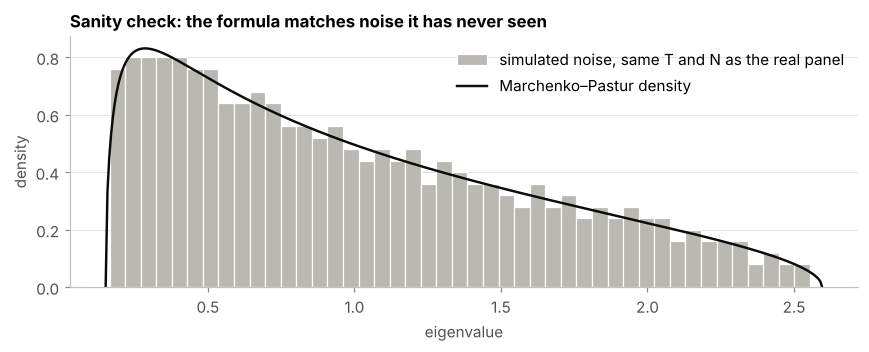

In [3]:
def mp_edges(q, sigma2=1.0):
    """Lower and upper edge of the Marchenko–Pastur bulk."""
    return sigma2 * (1 - np.sqrt(q)) ** 2, sigma2 * (1 + np.sqrt(q)) ** 2


def mp_density(lam, q, sigma2=1.0):
    """Marchenko–Pastur density at `lam` (zero outside the edges)."""
    lo, hi = mp_edges(q, sigma2)
    lam = np.asarray(lam, dtype=float)
    out = np.zeros_like(lam)
    inside = (lam > lo) & (lam < hi)
    out[inside] = (np.sqrt((hi - lam[inside]) * (lam[inside] - lo))
                   / (2 * np.pi * q * sigma2 * lam[inside]))
    return out


rng = np.random.default_rng(SEED)
noise_vals, _ = correlation_spectrum(rng.standard_normal((T, N)))
lam_minus, lam_plus = mp_edges(q)
print(f"MP edges for q = {q:.3f}:  [{lam_minus:.3f}, {lam_plus:.3f}]")
print(f"simulated Gaussian noise: smallest {noise_vals.min():.3f}, largest {noise_vals.max():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.3))
grid = np.linspace(lam_minus, lam_plus, 400)
ax.hist(noise_vals, bins=45, density=True, color=C.NULL_GREY, edgecolor="white",
        linewidth=0.8, label="simulated noise, same T and N as the real panel")
ax.plot(grid, mp_density(grid, q), color=C.INK, linewidth=1.6, label="Marchenko–Pastur density")
ax.set(xlabel="eigenvalue", ylabel="density",
       title="Sanity check: the formula matches noise it has never seen")
ax.legend(); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

The histogram follows the curve and nothing falls outside the edges. The
formula can be used.

## 3. The real spectrum against two nulls

The formula assumes Gaussian noise. Stock returns have fat tails, so there is
a fair objection that real "noise" might spill past $\lambda_+$ without any
true correlation being present. Rather than argue about it, build a second
null that makes no distributional assumption:

**Permutation null.** Shuffle each stock's return series *independently* in
time. Every stock keeps its exact return distribution, fat tails included, but
day $t$ for one stock no longer lines up with day $t$ for any other, so all
cross-correlation is destroyed. The largest eigenvalue of that scrambled
panel, over many shuffles, is an empirical noise edge.

In [4]:
def permutation_null_spectra(x, n_sims, rng):
    """Spectra of panels whose columns are independently shuffled in time."""
    spectra = np.empty((n_sims, x.shape[1]))
    for i in range(n_sims):
        # rng.permuted shuffles each column separately (axis=0 = along time)
        spectra[i] = correlation_spectrum(rng.permuted(x, axis=0))[0]
    return spectra


null_spectra = permutation_null_spectra(X, 100, np.random.default_rng(SEED + 1))
null_top = null_spectra[:, 0]
perm_edge = null_top.max()

n_above_mp = int((eigvals > lam_plus).sum())
n_above_perm = int((eigvals > perm_edge).sum())
print(f"analytic MP edge:                         {lam_plus:.3f}  -> {n_above_mp} eigenvalues above")
print(f"permutation null, largest of 100 shuffles: {perm_edge:.3f}  -> {n_above_perm} eigenvalues above")
print(f"  (largest eigenvalue per shuffle: mean {null_top.mean():.3f}, sd {null_top.std(ddof=1):.3f})")

analytic MP edge:                         2.596  -> 14 eigenvalues above
permutation null, largest of 100 shuffles: 2.633  -> 14 eigenvalues above
  (largest eigenvalue per shuffle: mean 2.566, sd 0.023)


The two nulls put the noise edge in almost the same place, so fat tails are
not doing anything dramatic here.

There is a subtler issue with both, and it changes the count. The first
eigenvalue is so large that it uses up a big share of the total variance
($\sum \lambda = N$ is fixed). The *remaining* eigenvalues are therefore
sharing less than $N$ between them, and comparing them to a noise bulk with
$\sigma^2 = 1$ is comparing them to noise that is too loud. The standard
correction (Laloux et al., 1999) refits the bulk with the variance the market
mode leaves behind:

$$\sigma^2 = 1 - \lambda_1 / N$$

market mode: lambda_1 = 141.7 = 30.1% of all variance
residual variance sigma^2 = 0.699  ->  adjusted upper edge 1.814
eigenvalues above adjusted edge: 26

variance carried by signal eigenvalues (26): 55.6%;  by the 444 bulk eigenvalues: 44.4%


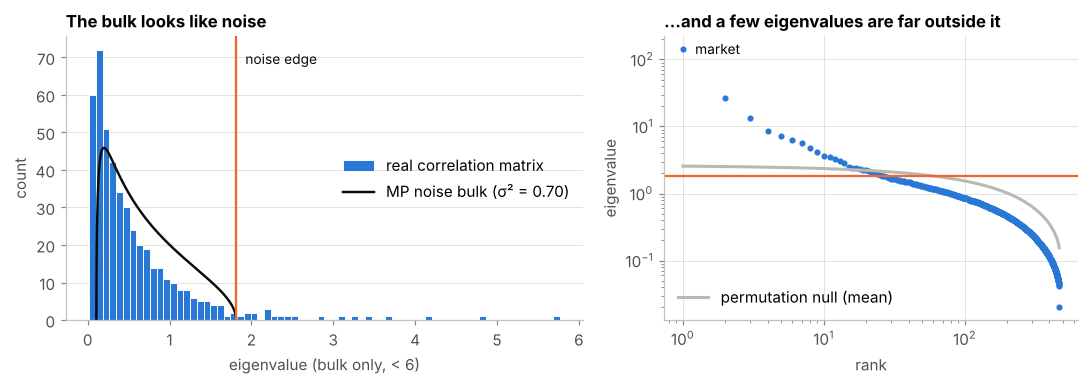

In [5]:
sigma2_resid = 1 - eigvals[0] / N
_, lam_plus_resid = mp_edges(q, sigma2_resid)
n_above_resid = int((eigvals > lam_plus_resid).sum())

print(f"market mode: lambda_1 = {eigvals[0]:.1f} = {eigvals[0]/N:.1%} of all variance")
print(f"residual variance sigma^2 = {sigma2_resid:.3f}  ->  adjusted upper edge {lam_plus_resid:.3f}")
print(f"eigenvalues above adjusted edge: {n_above_resid}")
print(f"\nvariance carried by signal eigenvalues ({n_above_resid}): "
      f"{eigvals[:n_above_resid].sum()/N:.1%};  by the {N - n_above_resid} bulk eigenvalues: "
      f"{eigvals[n_above_resid:].sum()/N:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]                      # the bulk, zoomed in
bulk_max = 6.0
ax.hist(eigvals[eigvals < bulk_max], bins=70, density=False, color=C.BLUE,
        edgecolor="white", linewidth=0.6, label="real correlation matrix")
grid = np.linspace(*mp_edges(q, sigma2_resid), 400)
# scale density -> counts so the curve is comparable to the histogram
bin_w = (eigvals[eigvals < bulk_max].max() - eigvals.min()) / 70
ax.plot(grid, mp_density(grid, q, sigma2_resid) * N * bin_w, color=C.INK, linewidth=1.6,
        label=f"MP noise bulk (σ² = {sigma2_resid:.2f})")
ax.axvline(lam_plus_resid, color=C.ORANGE, linewidth=1.5)
ax.annotate("noise edge", (lam_plus_resid, ax.get_ylim()[1] * 0.95), xytext=(6, 0),
            textcoords="offset points", va="top", fontsize=9, color=C.INK)
ax.set(xlabel="eigenvalue (bulk only, < 6)", ylabel="count", title="The bulk looks like noise")
ax.legend(loc="center right"); ax.grid(axis="x", visible=False)

ax = axes[1]                      # everything, on a log axis
rank = np.arange(1, N + 1)
ax.plot(rank, eigvals, color=C.BLUE, marker="o", markersize=3, linewidth=0)
ax.plot(rank, null_spectra.mean(axis=0), color=C.NULL_GREY, linewidth=2, label="permutation null (mean)")
ax.axhline(lam_plus_resid, color=C.ORANGE, linewidth=1.5)
ax.set(xscale="log", yscale="log", xlabel="rank", ylabel="eigenvalue",
       title="…and a few eigenvalues are far outside it")
ax.annotate("market", (1, eigvals[0]), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

So the honest answer to "how many factors?" is a range, and the range depends
on the null: 14 against a naive noise edge, 26 once the market mode's share
of the variance is accounted for. Either way it is a few percent of 470. The
other ~95% of eigenvalues, which between them hold about 44% of the variance,
are not distinguishable from what independent stocks would produce.

The left panel also shows where the fit is imperfect, and it should be said
rather than hidden: the real bulk is piled up nearer zero than the fitted
curve. The reason is that the adjustment only removed the market mode. The
other 25 signal eigenvalues also use up variance, so the true noise level is
lower still, and refitting would move the edge left and promote yet more
eigenvalues to "signal". The count is therefore a lower bound with a soft
upper end, and eigenvalues just above the edge deserve much less trust than
the top handful. A cleaner method fits $\sigma^2$ to the bulk directly; that
is a natural extension.

## 4. What the signal eigenvectors are

Each eigenvector is a portfolio: a weight on every stock. Two diagnostics.

- **Sector composition.** Which sectors are the largest positive and negative
  weights? (Sector labels are today's GICS list, so tickers that have since
  changed are unlabelled — see `common.load_sectors`.)
- **Inverse participation ratio**, $\text{IPR} = \sum_i v_i^4$. For a unit
  vector spread evenly over all $N$ stocks it is $1/N$; for a vector
  concentrated on one stock it is 1. Its reciprocal is the number of stocks
  that effectively participate.

In [6]:
sectors = C.load_sectors().reindex(tickers)
print(f"sector label found for {sectors.notna().sum()} of {N} tickers\n")

v1 = eigvecs[:, 0]
print(f"eigenvector 1: {max((v1 > 0).mean(), (v1 < 0).mean()):.0%} of weights share one sign; "
      f"1/IPR = {1/np.sum(v1**4):.0f} stocks participate (of {N})")
mkt_proxy = standardise(X).mean(axis=1)
print(f"correlation of its daily return with the equal-weighted market: "
      f"{abs(np.corrcoef(standardise(X) @ v1, mkt_proxy)[0, 1]):.4f}\n")


def describe_vector(k, n_show=15):
    """Dominant sectors among the n_show most positive / most negative weights."""
    v = eigvecs[:, k]
    order = np.argsort(v)

    def top_sectors(idx):
        counts = sectors.iloc[idx].value_counts()            # unlabelled tickers drop out
        return ", ".join(f"{s} ×{c}" for s, c in counts.head(2).items())

    return {"eigenvalue": round(eigvals[k], 1),
            "1/IPR": int(round(1 / np.sum(v ** 4))),
            "positive end": top_sectors(order[-n_show:]),
            "negative end": top_sectors(order[:n_show])}


vec_table = pd.DataFrame({f"vec {k+1}": describe_vector(k) for k in range(1, 7)}).T
with pd.option_context("display.max_colwidth", 60, "display.width", 200):
    print(vec_table.to_string())

sector label found for 331 of 470 tickers

eigenvector 1: 100% of weights share one sign; 1/IPR = 398 stocks participate (of 470)
correlation of its daily return with the equal-weighted market: 0.9984

      eigenvalue 1/IPR                                    positive end                               negative end
vec 2       26.6    98                                   Financials ×8                              Utilities ×15
vec 3       13.6    82                                       Energy ×6             Industrials ×3, Health Care ×3
vec 4        8.7   175       Information Technology ×8, Health Care ×5                             Financials ×11
vec 5        7.3   117  Consumer Staples ×2, Consumer Discretionary ×2    Information Technology ×9, Utilities ×4
vec 6        6.3   117  Consumer Staples ×8, Consumer Discretionary ×3                             Real Estate ×7
vec 7        5.8   128                                 Health Care ×11  Information Technology ×8, Real Estate ×3


**Eigenvector 1 is the market.** Every stock has the same sign, about 400 of
the 470 participate, and its daily return has a correlation of 0.998 with the
equal-weighted index. It was not told what the market is; it is simply the
direction of greatest shared variance.

**The next few are sectors, as long–short contrasts.** Because every
eigenvector must be orthogonal to the market, none of them can be "all
utilities up" — they come out as one group against another. The signs are
arbitrary; the pairings are not, and they are economically recognisable:
financials against utilities (the interest-rate trade), energy against the
rest, technology and health care against financials, consumer staples against
real estate. About 30% of tickers have no sector label, so these are read off
the labelled majority. The sign and exact ordering of neighbouring vectors should
not be over-read: eigenvectors with similar eigenvalues are only determined up
to rotation among themselves.

## 5. The internship's rank metrics, ported

The three functions below are `effective_rank`, `participation_ratio` and
`components_for_variance` from `Week_7/collapse_metrics.py`, with the PyTorch
dependency removed and nothing else changed. They take **singular values**,
exactly as they did for activations. For a standardised $T \times N$ matrix
the singular values $s_i$ and the correlation eigenvalues are related by
$\lambda_i = s_i^2 / T$.

In [7]:
def effective_rank(singular_values, eps=1e-12):
    """exp(Shannon entropy of the normalised singular value spectrum).

    Roy & Vetterli's effective rank. Equals k exactly when there are k equal
    singular values and the rest are zero, and varies continuously in between.
    """
    s = np.asarray(singular_values, dtype=np.float64)
    s = s[s > eps * (s.max() if s.size and s.max() > 0 else 1.0)]
    if s.size == 0:
        return 0.0
    p = s / s.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def participation_ratio(singular_values):
    """(sum s^2)^2 / sum s^4. Harsher than effective rank: it weights by squared
    variance, so one dominant direction with a long weak tail scores very low."""
    s2 = np.asarray(singular_values, dtype=np.float64) ** 2
    denom = (s2 ** 2).sum()
    return float((s2.sum() ** 2) / denom) if denom > 0 else 0.0


def components_for_variance(singular_values, target=0.90):
    """Number of principal components needed to reach `target` of the variance."""
    s2 = np.asarray(singular_values, dtype=np.float64) ** 2
    return int(np.searchsorted(np.cumsum(s2) / s2.sum(), target) + 1)


def rank_report(eigenvalues, t):
    """All four rank summaries for one spectrum of correlation eigenvalues."""
    lam = np.clip(eigenvalues, 0, None)
    s = np.sqrt(lam * t)                                  # back to singular values
    return {"effective rank (on singular values)": effective_rank(s),
            "effective rank (on eigenvalues)":     effective_rank(lam),
            "participation ratio":                  participation_ratio(s),
            "PR90":                                 components_for_variance(s)}


real_ranks = rank_report(eigvals, T)
null_ranks = pd.DataFrame([rank_report(sp, T) for sp in null_spectra]).mean()
rank_table = pd.DataFrame({"real market": real_ranks, "noise (permutation null)": null_ranks})
rank_table["real / noise"] = rank_table["real market"] / rank_table["noise (permutation null)"]
print(f"maximum possible: {N}\n")
print(rank_table.to_string(formatters={"real market": "{:.1f}".format,
                                       "noise (permutation null)": "{:.1f}".format,
                                       "real / noise": "{:.2f}".format}))

maximum possible: 470

                                    real market noise (permutation null) real / noise
effective rank (on singular values)       377.4                    445.2         0.85
effective rank (on eigenvalues)            78.3                    389.9         0.20
participation ratio                        10.3                    342.2         0.03
PR90                                      224.0                    334.9         0.67


Four summaries of the *same* spectrum, and they range from "about ten" to
"nearly four hundred". None of them is wrong. They weight the tail
differently:

- Entropy of the **singular values** is gentle on small values, so 450
  noise-level directions each count for something and the answer is large.
- Entropy of the **eigenvalues** (variances) squares that weighting.
- The **participation ratio** squares it again, and ends up dominated by the
  market mode.
- **PR90** just counts until 90% of variance is covered.

This is the Week 7 observation — "both effective rank and PR90 are recorded
deliberately; the gap between them turns out to be the finding" — in a setting
where the reason is visible: one enormous direction plus a long flat tail is
exactly the spectrum shape on which these measures disagree most.

The second column is the one that makes any of the numbers interpretable.
**Pure noise does not score 470.** With $q = 0.37$ even perfectly independent
stocks produce a spread-out sample spectrum and an effective rank well below
$N$. Week 7 made the same point about width ("once H exceeds the data's
intrinsic dimensionality, rank/H must fall however healthy the layer is —
only the between-variant comparisons carry weight"). Here the comparison that
carries weight is real against noise at the same $T$ and $N$, which is the
last column — and there the four measures still disagree, from "the market
has 85% of the independent directions noise would" to "it has 3%". Which one
is right depends on the question. For "how concentrated is risk?" the
participation ratio is the relevant one; for "how many directions would I need
to keep?" it is PR90. Reporting a single rank number without saying which, and
without the noise reference beside it, is not informative.

## 6. Through time: when the market collapses onto one direction

Everything above treated five years as one sample. Correlations are not
constant, and the interesting question for risk is when they rise. Slide a
126-day (six-month) window through the sample and recompute the spectrum at
each step.

In a 126-day window there are more stocks than days ($q \approx 3.7$), so the
correlation matrix has at most 125 non-zero eigenvalues and the eigenvalue
route is wasteful. The singular values of the $126 \times 470$ window give the
same non-zero spectrum directly — the same reason `collapse_metrics.py` worked
from `svdvals` of the activation matrix rather than forming a covariance.

In [8]:
WINDOW, STEP = 126, 5


def rolling_structure(x, window, step):
    """Market-mode share and rank metrics for each rolling window."""
    rows = []
    for end in range(window, len(x) + 1, step):
        z = standardise(x[end - window:end])            # re-standardise inside the window
        s = np.linalg.svd(z, compute_uv=False)          # singular values only: fast
        lam = s ** 2 / window                           # non-zero correlation eigenvalues
        rows.append({"end": end - 1,
                     "market share": lam[0] / lam.sum(),
                     "effective rank": effective_rank(lam),
                     "participation ratio": participation_ratio(s)})
    return pd.DataFrame(rows)


roll = rolling_structure(X, WINDOW, STEP)
roll.index = rets.index[roll.pop("end")]

# the matched null for THIS window shape: independently shuffled columns
rng = np.random.default_rng(SEED + 2)
null_roll = pd.concat([rolling_structure(rng.permuted(X, axis=0), WINDOW, 60) for _ in range(5)])
null_share, null_rank = null_roll["market share"].mean(), null_roll["effective rank"].mean()

# realised volatility of the equal-weighted market over the same windows
mkt = rets.mean(axis=1)
roll["market vol"] = (mkt.rolling(WINDOW).std() * np.sqrt(C.TRADING_DAYS)).reindex(roll.index)

print(f"{len(roll)} windows of {WINDOW} days, every {STEP} days  (max possible rank {WINDOW - 1})")
print(f"noise reference at this window shape: market share {null_share:.3f}, effective rank {null_rank:.1f}\n")
print(roll.describe().loc[["min", "50%", "max"]].to_string(float_format="%.3f"))
hi, lo = roll["market share"].idxmax(), roll["market share"].idxmin()
print(f"\nmost concentrated window ends  {hi.date()}: market share {roll.loc[hi, 'market share']:.1%}, "
      f"effective rank {roll.loc[hi, 'effective rank']:.1f}")
print(f"least concentrated window ends {lo.date()}: market share {roll.loc[lo, 'market share']:.1%}, "
      f"effective rank {roll.loc[lo, 'effective rank']:.1f}")
print(f"\ncorrelation between market-mode share and realised market volatility: "
      f"{roll['market share'].corr(roll['market vol']):+.2f}")

227 windows of 126 days, every 5 days  (max possible rank 125)
noise reference at this window shape: market share 0.018, effective rank 109.5

     market share  effective rank  participation ratio  market vol
min         0.129          18.896                4.291       0.065
50%         0.331          34.315                8.461       0.120
max         0.476          63.894               30.396       0.212

most concentrated window ends  2015-10-08: market share 47.6%, effective rank 18.9
least concentrated window ends 2018-01-05: market share 12.9%, effective rank 63.6

correlation between market-mode share and realised market volatility: +0.91


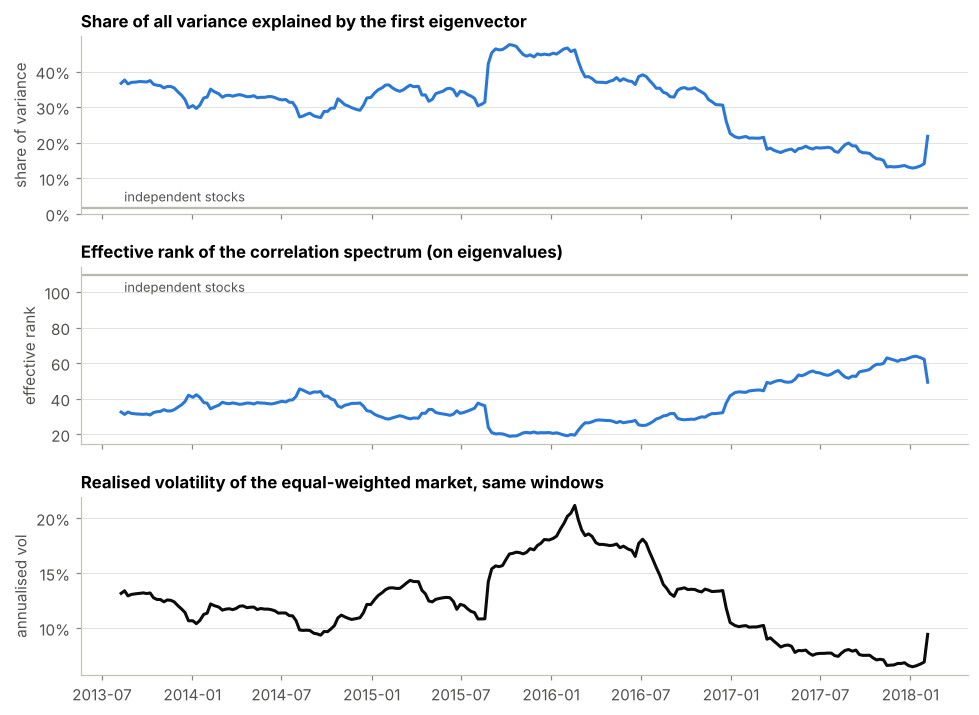

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6.6), sharex=True)
panels = [("market share", "share of variance", "Share of all variance explained by the first eigenvector", C.BLUE, null_share),
          ("effective rank", "effective rank", "Effective rank of the correlation spectrum (on eigenvalues)", C.BLUE, null_rank),
          ("market vol", "annualised vol", "Realised volatility of the equal-weighted market, same windows", C.INK, None)]
for ax, (col, ylab, title, colour, ref) in zip(axes, panels):
    ax.plot(roll.index, roll[col], color=colour)
    if ref is not None:
        ax.axhline(ref, color=C.NULL_GREY, linewidth=1.5)
        below = col == "effective rank"            # keep the label clear of the panel title
        ax.annotate("independent stocks", (roll.index[0], ref), xytext=(2, -11 if below else 4),
                    textcoords="offset points", fontsize=8.5, color="#52514e")
    ax.set(ylabel=ylab, title=title)
    ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylim(bottom=0)
plt.tight_layout(); plt.show()

The date on the x-axis is the *end* of each six-month window, so a feature
appears when an event enters the window and lingers until it leaves.

**What the figure shows.** The market mode's share of variance is never
anywhere near the 2% that independent stocks would give, but it is far from
constant: it ranges from 13% to 48%. The jump in late August 2015 is the
China-devaluation sell-off entering the window; the share stays near its peak
through the early-2016 sell-off and then decays. Through 2017, the calmest
year for US equities in decades, it falls to its minimum and the effective
rank more than triples from its low. The final uptick is the first days of
the February 2018 volatility spike, which the sample ends in the middle of.

**Collapse and volatility move together** (correlation +0.91 with realised
market volatility). Two cautions about that number. First, it is partly
arithmetic: when the common factor gets more volatile and stock-specific
noise does not, the common factor's *share* of variance must rise, so some
of this is a restatement rather than a discovery. Second, the windows overlap
heavily (126 days, stepped by 5), so the 227 points are nowhere near 227
independent observations — there are perhaps ten non-overlapping windows in
the sample, and effectively one stress episode. The direction is not in doubt;
the 0.91 should not be quoted as if it had a tight confidence interval.

For a risk manager the consequence is the familiar and uncomfortable one:
diversification is weakest exactly when it is needed. In the autumn of 2015 a
470-stock portfolio behaved like one built from about 19 independent bets.

## 7. Does it matter? Denoising the covariance matrix

So far this is description. The test of whether the signal/noise split means
anything is whether acting on it improves a decision made out of sample.

**The decision.** Build the minimum-variance portfolio: the weights
$w \propto \Sigma^{-1}\mathbf{1}$ that minimise predicted variance. It needs
the *inverse* of the covariance matrix, and inversion is exactly where noise
hurts: the smallest eigenvalues become the largest after inverting, and the
smallest eigenvalues are the noisiest. The optimiser finds combinations of
stocks that *looked* almost riskless in the estimation window by chance and
loads up on them.

**Four estimators of $\Sigma$**, all given the same 250 days:

| estimator | idea |
|---|---|
| sample | the raw sample covariance |
| RMT-clipped | keep eigenvalues above the noise edge; replace every eigenvalue in the noise bulk by the bulk's average |
| Ledoit–Wolf | shrink the sample matrix towards a multiple of the identity, by an analytically optimal amount |
| equal weight | ignore $\Sigma$ entirely and hold $1/N$ of each stock (the "do nothing" control) |

**Protocol.** Draw 100 stocks at random. Every 21 days: estimate on the
previous 250 days, form the portfolio, hold it for the next 21 days, record
its daily returns. Then measure the realised volatility of those
out-of-sample returns. Repeat for 30 different random draws of 100 stocks, so
every figure has a standard error — the multi-seed habit from the internship,
with "seed" now meaning which stocks were drawn.

In [10]:
def clip_covariance(x):
    """RMT eigenvalue clipping (Laloux et al. / Bouchaud & Potters).

    Work on the CORRELATION matrix (so every stock is on the same scale and the
    MP law applies), flatten the noise bulk, then put the volatilities back.
    """
    t, n = x.shape
    vol = x.std(axis=0)
    z = (x - x.mean(axis=0)) / vol
    vals, vecs = np.linalg.eigh(z.T @ z / t)              # ascending
    sigma2 = 1 - vals[-1] / n                             # variance left after the market mode
    _, edge = mp_edges(n / t, sigma2)
    noise = vals < edge
    cleaned = vals.copy()
    cleaned[noise] = vals[noise].mean()                   # trace is preserved
    corr = (vecs * cleaned) @ vecs.T                      # V diag(cleaned) V^T
    d = np.sqrt(np.diag(corr))
    corr = corr / np.outer(d, d)                          # restore an exact unit diagonal
    return corr * np.outer(vol, vol), int((~noise).sum())


def min_variance_weights(cov):
    """w = inv(cov) 1 / (1' inv(cov) 1): fully invested, shorting allowed.

    np.linalg.solve(cov, ones) computes inv(cov) @ ones without ever forming
    the inverse, which is both faster and numerically safer.
    """
    w = np.linalg.solve(cov, np.ones(len(cov)))
    return w / w.sum()


ESTIMATORS = {
    "sample":      lambda x: np.cov(x, rowvar=False),
    "RMT-clipped": lambda x: clip_covariance(x)[0],
    "Ledoit–Wolf": lambda x: LedoitWolf().fit(x).covariance_,
}


def out_of_sample_vol(x, lookback=250, hold=21):
    """Annualised realised vol (and gross leverage) of each rolling portfolio."""
    daily = {name: [] for name in [*ESTIMATORS, "equal weight"]}
    leverage = {name: [] for name in ESTIMATORS}
    for start in range(lookback, len(x) - hold + 1, hold):
        past, future = x[start - lookback:start], x[start:start + hold]
        for name, estimate in ESTIMATORS.items():
            w = min_variance_weights(estimate(past))
            daily[name].append(future @ w)
            leverage[name].append(np.abs(w).sum())        # 1.0 = long-only
        daily["equal weight"].append(future.mean(axis=1))
    vol = {k: np.concatenate(v).std(ddof=1) * np.sqrt(C.TRADING_DAYS) for k, v in daily.items()}
    lev = {k: float(np.mean(v)) for k, v in leverage.items()}
    lev["equal weight"] = 1.0                             # long-only by construction
    return vol, lev


N_SUB, N_DRAWS = 100, 30
simple = np.expm1(X)                       # portfolio returns add in SIMPLE returns
rng = np.random.default_rng(SEED + 3)
vols, levs, n_signal = [], [], []
for _ in range(N_DRAWS):
    cols = rng.choice(N, size=N_SUB, replace=False)
    v, l = out_of_sample_vol(simple[:, cols])
    vols.append(v); levs.append(l)
    n_signal.append(clip_covariance(simple[-250:, cols])[1])
vols, levs = pd.DataFrame(vols), pd.DataFrame(levs)

sem = lambda d: d.std(ddof=1) / np.sqrt(len(d))
pf = pd.DataFrame({"out-of-sample vol": vols.mean(), "SEM": sem(vols),
                   "gross leverage": levs.mean()}).loc[["equal weight", "sample", "Ledoit–Wolf", "RMT-clipped"]]
print(f"{N_DRAWS} draws of {N_SUB} stocks, 250-day estimation window (q = {N_SUB/250:.2f}), 21-day holding\n")
print(pf.to_string(formatters={"out-of-sample vol": "{:.2%}".format, "SEM": "{:.2%}".format,
                               "gross leverage": "{:.2f}".format}))
print(f"\neigenvalues kept as signal by the clipping (last window): "
      f"{np.mean(n_signal):.1f} of {N_SUB} on average")

# paired differences: every estimator saw the same stocks and the same days
print("\npaired difference in out-of-sample vol, in SEMs of the difference:")
for a, b in [("sample", "RMT-clipped"), ("sample", "Ledoit–Wolf"), ("Ledoit–Wolf", "RMT-clipped")]:
    d = vols[a] - vols[b]
    print(f"  {a:12s} minus {b:12s}: {d.mean():+.2%}  ({d.mean()/sem(d):+.1f} SEM, "
          f"{b} lower in {np.mean(d > 0):.0%} of draws)")

30 draws of 100 stocks, 250-day estimation window (q = 0.40), 21-day holding

             out-of-sample vol   SEM gross leverage
equal weight            12.87% 0.06%           1.00
sample                  11.93% 0.08%           4.80
Ledoit–Wolf             10.50% 0.07%           3.32
RMT-clipped             10.42% 0.06%           2.77

eigenvalues kept as signal by the clipping (last window): 7.0 of 100 on average

paired difference in out-of-sample vol, in SEMs of the difference:
  sample       minus RMT-clipped : +1.51%  (+29.3 SEM, RMT-clipped lower in 100% of draws)
  sample       minus Ledoit–Wolf : +1.42%  (+69.3 SEM, Ledoit–Wolf lower in 100% of draws)
  Ledoit–Wolf  minus RMT-clipped : +0.08%  (+1.9 SEM, RMT-clipped lower in 70% of draws)


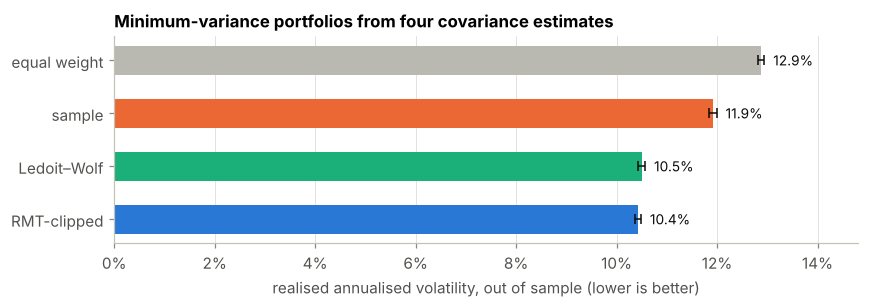

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.9))
order = ["equal weight", "sample", "Ledoit–Wolf", "RMT-clipped"][::-1]
colours = {"equal weight": C.NULL_GREY, "sample": C.ORANGE, "Ledoit–Wolf": C.AQUA, "RMT-clipped": C.BLUE}
ax.barh(order, pf.loc[order, "out-of-sample vol"], height=0.55, color=[colours[o] for o in order],
        xerr=pf.loc[order, "SEM"], error_kw=dict(ecolor=C.INK, elinewidth=1, capsize=3))
for i, o in enumerate(order):
    ax.annotate(f"{pf.loc[o, 'out-of-sample vol']:.1%}", (pf.loc[o, "out-of-sample vol"], i),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=C.INK)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="realised annualised volatility, out of sample (lower is better)",
       title="Minimum-variance portfolios from four covariance estimates")
ax.set_xlim(0, pf["out-of-sample vol"].max() * 1.15)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

The comparisons are **paired** — every estimator was given the same stocks on
the same days — so differences are tested on the per-draw differences, not by
eyeballing error bars.

**What it shows.**

- **The raw sample covariance is the worst way to use the data.** Its
  minimum-variance portfolio is only about a point less volatile than holding
  everything equally, and it gets there with gross leverage near 5 (for every
  £1 invested, roughly £2.90 long and £1.90 short). That leverage is the
  optimiser betting on noise.
- **Both cleaning methods help, by about 1.5 points of volatility** (a 12–13%
  relative reduction), in 30 of 30 draws, with far less leverage. Telling the
  estimator which eigenvalues are noise is worth more than the entire gap
  between optimising and not optimising.
- **Clipping against Ledoit–Wolf is not settled.** Clipping is lower by 0.08
  points, 1.9 standard errors, in 70% of draws. By the rule used throughout
  the internship — differences near the noise floor are not read — that is a
  tie, not a win for the random-matrix method.

**A warning about the standard errors.** The 30 draws are 30 different sets of
stocks, but they are drawn from the same 470 names and live through the same
four years. They share one history. The SEMs describe sensitivity to *which
stocks*, not to *which period*, and so they understate the real uncertainty.
"30 of 30" would not survive as a claim about a different decade without
being re-run on one.

## 8. What was found

Every number in the table is computed by the cell, not typed.

In [12]:
d_sc, d_lc = vols["sample"] - vols["RMT-clipped"], vols["Ledoit–Wolf"] - vols["RMT-clipped"]
summary = pd.DataFrame([
    ("stocks / days / q",                                     f"{N} / {T} / {q:.2f}"),
    ("variance in the market mode, full sample",              f"{eigvals[0]/N:.1%}"),
    ("eigenvalues above the naive MP edge",                   f"{n_above_mp}"),
    ("eigenvalues above the largest permutation-null value",  f"{n_above_perm}"),
    ("eigenvalues above the market-adjusted edge",            f"{n_above_resid}"),
    ("effective rank, real vs noise (eigenvalue form)",       f"{real_ranks['effective rank (on eigenvalues)']:.0f} vs {null_ranks['effective rank (on eigenvalues)']:.0f}"),
    ("participation ratio, real vs noise",                    f"{real_ranks['participation ratio']:.0f} vs {null_ranks['participation ratio']:.0f}"),
    ("market-mode share, rolling 126d: min / max",            f"{roll['market share'].min():.0%} / {roll['market share'].max():.0%}"),
    ("correlation of market-mode share with realised vol",    f"{roll['market share'].corr(roll['market vol']):+.2f}"),
    ("min-variance OOS vol: sample / Ledoit–Wolf / clipped",  f"{pf.loc['sample','out-of-sample vol']:.1%} / {pf.loc['Ledoit–Wolf','out-of-sample vol']:.1%} / {pf.loc['RMT-clipped','out-of-sample vol']:.1%}"),
    ("clipped vs sample, paired",                             f"{d_sc.mean():+.2%} ({d_sc.mean()/sem(d_sc):+.1f} SEM)"),
    ("clipped vs Ledoit–Wolf, paired",                        f"{d_lc.mean():+.2%} ({d_lc.mean()/sem(d_lc):+.1f} SEM)"),
], columns=["quantity", "value"])
print(summary.to_string(index=False))

                                            quantity                 value
                                   stocks / days / q     470 / 1258 / 0.37
            variance in the market mode, full sample                 30.1%
                 eigenvalues above the naive MP edge                    14
eigenvalues above the largest permutation-null value                    14
          eigenvalues above the market-adjusted edge                    26
     effective rank, real vs noise (eigenvalue form)             78 vs 390
                  participation ratio, real vs noise             10 vs 342
          market-mode share, rolling 126d: min / max             13% / 48%
  correlation of market-mode share with realised vol                 +0.91
min-variance OOS vol: sample / Ledoit–Wolf / clipped 11.9% / 10.5% / 10.4%
                           clipped vs sample, paired    +1.51% (+29.3 SEM)
                      clipped vs Ledoit–Wolf, paired     +0.08% (+1.9 SEM)


### What this establishes

1. **Most of a large correlation matrix is noise, and the amount is
   calculable.** Of 470 eigenvalues, between 14 and 26 exceed what independent
   stocks would produce, depending on the null. The Marchenko–Pastur edge was
   checked on simulated noise and against a distribution-free permutation
   null before being relied on.
2. **One direction dominates.** The market mode carries 30% of all variance
   over the full sample, and the next few eigenvectors are recognisable sector
   contrasts.
3. **A rank statistic is only meaningful beside its noise reference.** Four
   rank summaries of the same spectrum span 10 to 377, and independent stocks
   at this $T$ and $N$ score well below $N$ on all of them.
4. **Concentration is not constant.** The market mode's share moved between
   13% and 48% within five years, rising with volatility.
5. **The split is useful, not just descriptive.** Cleaning the covariance
   matrix cut out-of-sample minimum-variance volatility by about 1.5 points
   relative to the raw estimate, in every draw.

### What it does not establish

- **Survivorship bias.** The universe is index membership as of 2018. Stocks
  that failed are absent, which removes exactly the names with the most
  extreme idiosyncratic behaviour.
- **One calm period.** 2013–2018 contains no 2008 and no 2020. The largest
  stress event is August 2015. Everything about "collapse in a crisis" is
  extrapolated from one modest episode.
- **Clipping is not shown to beat shrinkage.** The 1.9-SEM difference is not a
  result, and the SEMs are optimistic for the reason given above.
- **The signal count has a soft upper end.** The bulk fit removes only the
  market mode; a proper bulk fit would move the edge.
- **Stationarity.** Eigen-*values* were tracked through time; whether the
  eigen-*vectors* (the factors themselves) are stable from window to window
  was not tested, and denoising quietly assumes they are stable enough.

### Where to take it next

1. **Fit the bulk directly** (choose $\sigma^2$ and $q$ to match the bulk's
   histogram) and report how the signal count changes — it closes the open end
   of finding 1.
2. **Eigenvector stability.** Measure the overlap between the top-$k$
   subspaces of consecutive non-overlapping windows. This is the linear-probe
   question from the Week 7 next-steps slide in another form: are the
   directions being kept the same directions next period?
3. **A longer, survivorship-free sample.** If the university has WRDS access,
   CRSP daily returns from 2000 give two real crises and point-in-time index
   membership. That one change would upgrade findings 4 and 5 from suggestive
   to solid.
4. **Better denoisers.** Rotationally-invariant (non-linear shrinkage)
   estimators are the current state of the art and the natural third column
   in the Section 7 table.

### References

- Laloux, Cizeau, Bouchaud & Potters (1999), *Noise dressing of financial correlation matrices*, Physical Review Letters.
- Plerou et al. (2002), *Random matrix approach to cross correlations in financial data*, Physical Review E.
- Bun, Bouchaud & Potters (2017), *Cleaning large correlation matrices: tools from random matrix theory*, Physics Reports.
- Ledoit & Wolf (2004), *A well-conditioned estimator for large-dimensional covariance matrices*, Journal of Multivariate Analysis.
- Roy & Vetterli (2007), *The effective rank: a measure of effective dimensionality*, EUSIPCO.